In [276]:
import pandas as pd
import numpy as np
import seaborn as sns # a ploting library based on matplotlib
import matplotlib.pyplot as plt

# Preprocessing
removing or replacing the Null values

In [277]:
df = pd.read_csv("../data/raw/H2.csv", na_values=['NULL'], skipinitialspace=True)

In [278]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
IsCanceled,79330.0,NaN,NaN,NaN,0.41727,0.493111,0.0,0.0,0.0,1.0,1.0
LeadTime,79330.0,NaN,NaN,NaN,109.735724,110.948526,0.0,23.0,74.0,163.0,629.0
ArrivalDateYear,79330.0,NaN,NaN,NaN,2016.174285,0.699181,2015.0,2016.0,2016.0,2017.0,2017.0
ArrivalDateMonth,79330,12,August,8983,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ArrivalDateWeekNumber,79330.0,NaN,NaN,NaN,27.177449,13.398523,1.0,17.0,27.0,38.0,53.0
ArrivalDateDayOfMonth,79330.0,NaN,NaN,NaN,15.786625,8.728451,1.0,8.0,16.0,23.0,31.0
StaysInWeekendNights,79330.0,NaN,NaN,NaN,0.795185,0.885026,0.0,0.0,1.0,2.0,16.0
StaysInWeekNights,79330.0,NaN,NaN,NaN,2.182957,1.456416,0.0,1.0,2.0,3.0,41.0
Adults,79330.0,NaN,NaN,NaN,1.850977,0.509292,0.0,2.0,2.0,2.0,4.0
Children,79326.0,NaN,NaN,NaN,0.09137,0.372177,0.0,0.0,0.0,0.0,3.0


In [279]:
for c in df.select_dtypes(include=[str,'object']):
    print(c,df[c].isin(['NULL','NA','Undefined','','NaN']).sum())

ArrivalDateMonth 0
Meal 0
Country 0
MarketSegment 2
DistributionChannel 4
ReservedRoomType 0
AssignedRoomType 0
DepositType 0
CustomerType 0
ReservationStatus 0
ReservationStatusDate 0


### Fixing MarketSegment

In [280]:
df["MarketSegment"].unique()

<StringArray>
['Offline TA/TO',     'Online TA',        'Groups', 'Complementary',
        'Direct',     'Corporate',     'Undefined',      'Aviation']
Length: 8, dtype: str

In [281]:
df[df["MarketSegment"] == 'Undefined']

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
540,1,2,2015,August,32,3,1,0,2,NaN,...,No Deposit,NaN,NaN,0,Transient-Party,12.0,0,1,Canceled,2015-08-01
619,1,1,2015,August,32,5,0,2,3,NaN,...,No Deposit,NaN,NaN,0,Transient-Party,18.0,0,2,Canceled,2015-08-04


In [282]:
df = df[df["MarketSegment"] != "Undefined"]

In [283]:
df["MarketSegment"].unique()

<StringArray>
['Offline TA/TO',     'Online TA',        'Groups', 'Complementary',
        'Direct',     'Corporate',      'Aviation']
Length: 7, dtype: str

### fixing DistributionChannel

In [284]:
df["DistributionChannel"].unique()

<StringArray>
['TA/TO', 'Direct', 'Corporate', 'Undefined', 'GDS']
Length: 5, dtype: str

In [285]:
df[df["DistributionChannel"].isin(['NULL','NA','Undefined',''])]

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
607,1,1,2015,August,32,5,0,2,2,NaN,...,No Deposit,14.0,NaN,0,Transient-Party,12.0,0,1,Canceled,2015-08-04
1100,1,8,2015,August,33,13,2,5,2,NaN,...,No Deposit,9.0,NaN,0,Transient-Party,76.5,0,1,Canceled,2015-08-09


In [286]:
df = df[df["DistributionChannel"] != "Undefined"]

In [287]:
df["DistributionChannel"].unique()

<StringArray>
['TA/TO', 'Direct', 'Corporate', 'GDS']
Length: 4, dtype: str

---

In [288]:
df_string_columns = df.select_dtypes(include=[str,'object'])

In [289]:
df_string_columns.head()

,ArrivalDateMonth,Meal,Country,MarketSegment,DistributionChannel,ReservedRoomType,AssignedRoomType,DepositType,CustomerType,ReservationStatus,ReservationStatusDate
0,July,HB,PRT,Offline TA/TO,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-07-03
1,July,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Canceled,2015-07-01
2,July,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Canceled,2015-04-30
3,July,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Canceled,2015-06-23
4,July,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Canceled,2015-04-02


In [290]:
for c in df_string_columns.columns:
    print(c, df_string_columns[c].unique())

ArrivalDateMonth <StringArray>
[     'July',    'August', 'September',   'October',  'November',  'December',
   'January',  'February',     'March',     'April',       'May',      'June']
Length: 12, dtype: str
Meal <StringArray>
['HB       ', 'BB       ', 'SC       ', 'FB       ']
Length: 4, dtype: str
Country <StringArray>
['PRT', 'ITA', 'ESP', 'DEU', 'FRA', 'NLD', 'GBR', 'ROU', 'BRA', 'SWE',
 ...
 'SUR', 'MRT', 'CAF', 'NCL', 'KIR', 'SDN', 'ATF', 'SLE', 'LAO', 'COM']
Length: 167, dtype: str
MarketSegment <StringArray>
['Offline TA/TO',     'Online TA',        'Groups', 'Complementary',
        'Direct',     'Corporate',      'Aviation']
Length: 7, dtype: str
DistributionChannel <StringArray>
['TA/TO', 'Direct', 'Corporate', 'GDS']
Length: 4, dtype: str
ReservedRoomType <StringArray>
['A               ', 'B               ', 'D               ',
 'F               ', 'E               ', 'G               ',
 'C               ', 'P               ']
Length: 8, dtype: str
AssignedRoomType <

In [291]:
df["Company"].unique()

array([ nan,  40.,  45.,  38.,   9.,  47.,  49.,  51.,  48.,  62.,  67.,
        68.,  84.,  65.,  91.,  37.,   8.,  14., 174., 207., 179., 209.,
       219.,  72., 221., 227., 153., 186., 218.,  78., 253., 202., 216.,
       275., 277., 233., 280., 309., 321., 331.,  93., 316.,  85., 107.,
       350., 279., 334., 348., 405., 366., 365., 407., 242., 435., 150.,
        73., 428., 385., 418., 197., 409., 450., 452., 169., 466.,  43.,
       115., 465., 329.,  46.,  76.,  96., 358., 100., 108., 110.,  81.,
       120., 116., 105., 101., 122.,  11., 135., 137., 139., 144., 142.,
       127., 130., 143., 148., 140., 149., 163., 160., 180., 238., 183.,
       222., 203., 185., 217., 215., 193., 213., 224., 237., 230., 234.,
        35., 246., 245., 251., 255., 158., 258., 259., 260., 263., 411.,
       254., 272., 257., 271.,  18., 106., 210., 273., 278.,  71., 284.,
       292., 282., 301., 305., 307., 293., 264., 311., 304., 308., 313.,
       288., 312., 317., 320., 314., 332., 333., 34

In [292]:
df["Company"].isnull().sum()

np.int64(75637)

In [293]:
df['Country'].isnull().sum()

np.int64(24)

In [294]:
df[df['Country'].isnull()]['Country']

4831     NaN
4832     NaN
4833     NaN
4834     NaN
4835     NaN
4836     NaN
4837     NaN
4838     NaN
4839     NaN
4841     NaN
4842     NaN
4843     NaN
4844     NaN
4845     NaN
20591    NaN
21184    NaN
21185    NaN
21189    NaN
25847    NaN
25848    NaN
25849    NaN
25850    NaN
40770    NaN
61428    NaN
Name: Country, dtype: str

In [295]:
df["Country"] = df["Country"].fillna("Unknown")

In [296]:
df['Country'].isnull().sum()

np.int64(0)

In [297]:
df["Agent"].isnull().sum()

np.int64(8129)

In [298]:
df["Agent"].unique()

array([  6.,   9.,   1.,   8.,  13.,  11.,   7.,  15.,  nan,  27.,  14.,
        22.,  17.,  10.,  28.,  42.,   3.,  20.,  19.,  40.,  45.,  34.,
        37.,  57.,  61.,  16.,  39.,  21.,  24.,  69.,  41.,  50.,  30.,
        54.,  52.,  12.,  44.,  26.,  64.,  31.,  29.,  83.,  32.,  63.,
        66.,  60.,  55.,  56.,  89., 159., 155.,  38.,  91.,  87., 118.,
        86., 134.,  85.,  94., 210., 214., 129., 179., 138., 174., 154.,
       170., 182., 153.,  93., 151., 119.,  35., 168.,   2., 147., 195.,
       173.,  58.,  53., 128., 133.,  79., 152., 235., 192.,   5., 171.,
       191., 187., 236., 162., 215., 270., 157., 281., 177., 287., 240.,
       132., 331., 234.,  98.,  77., 103., 107., 262., 355., 220., 104.,
       330., 326., 121., 254., 205., 378.,  23., 296., 290., 229., 390.,
        33., 286.,  47., 276., 425., 315., 484., 323., 403., 219., 394.,
       509., 111., 423.,   4.,  71.,  78.,  72.,  75.,  70.,  82.,  81.,
        74.,  92.,  99.,  90.,  95., 112., 117., 10

In [299]:
df.isnull().sum()

IsCanceled                         0
LeadTime                           0
ArrivalDateYear                    0
ArrivalDateMonth                   0
ArrivalDateWeekNumber              0
ArrivalDateDayOfMonth              0
StaysInWeekendNights               0
StaysInWeekNights                  0
Adults                             0
Children                           0
Babies                             0
Meal                               0
Country                            0
MarketSegment                      0
DistributionChannel                0
IsRepeatedGuest                    0
PreviousCancellations              0
PreviousBookingsNotCanceled        0
ReservedRoomType                   0
AssignedRoomType                   0
BookingChanges                     0
DepositType                        0
Agent                           8129
Company                        75637
DaysInWaitingList                  0
CustomerType                       0
ADR                                0
R

### Checking for Anomalies

#### removing rows where total guests == 0
 this also removes any row with children/babies but no adult, which is ofcourse invalid

In [300]:
unaccompanied = df[(df["Adults"] == 0) & ((df["Children"] > 0) | (df["Babies"] > 0))]
print(len(unaccompanied))

223


In [301]:
df = df[df["Adults"] > 0]

In [302]:
unaccompanied = df[(df["Adults"] == 0) & ((df["Children"] > 0) | (df["Babies"] > 0))]
print(len(unaccompanied))

0


In [303]:
df["TotalGuests"] = df["Adults"] + df["Children"] + df["Babies"]

In [304]:
df[df["TotalGuests"] == 0]

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate,TotalGuests


In [305]:
df["IsFamily"] = (
    (df["Adults"] > 0) & ((df["Children"] + df["Babies"]) > 0)
).astype(int)

print(df["IsFamily"].value_counts())

IsFamily
0    73756
1     5180
Name: count, dtype: int64


In [306]:
df["Children"].unique()

array([0., 1., 2., 3.])

## Visuals and Plots

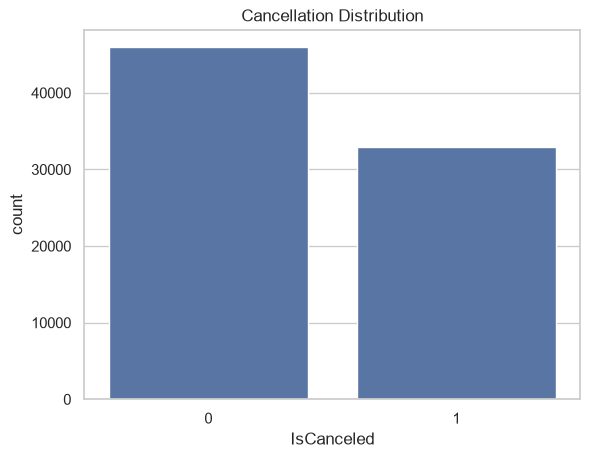

In [307]:
sns.countplot(data=df,x="IsCanceled") #creates a countplot(essentially a histogram) to using the data in df spicifically the column IsCanceled.
plt.title("Cancellation Distribution")
plt.show()

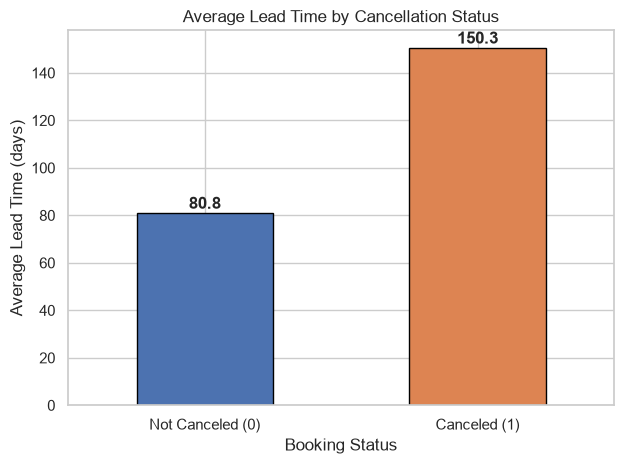

In [308]:
import matplotlib.pyplot as plt

avg_lead = df.groupby("IsCanceled")["LeadTime"].mean()

ax = avg_lead.plot(kind="bar", color=["#4C72B0", "#DD8452"], edgecolor="black")
ax.set_xticklabels(["Not Canceled (0)", "Canceled (1)"], rotation=0)
ax.set_xlabel("Booking Status")
ax.set_ylabel("Average Lead Time (days)")
ax.set_title("Average Lead Time by Cancellation Status")

# Show the value on top of each bar
for i, v in enumerate(avg_lead):
    ax.text(i, v + 2, f"{v:.1f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

In [309]:
sns.set_theme(style="whitegrid")

def cancel_rate_bar(col, title, order=None, min_count=0):
    counts = df[col].value_counts()
    keep = counts[counts >= min_count].index
    rates = df[df[col].isin(keep)].groupby(col)["IsCanceled"].mean()
    if order is not None:
        rates = rates.reindex([o for o in order if o in rates.index])
    else:
        rates = rates.sort_values(ascending=False)
    ax = rates.plot(kind="bar", color="#4C72B0", edgecolor="black")
    ax.set_ylabel("Cancellation Rate")
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
    for i, v in enumerate(rates):
        ax.text(i, v + 0.02, f"{v:.0%}", ha="center")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

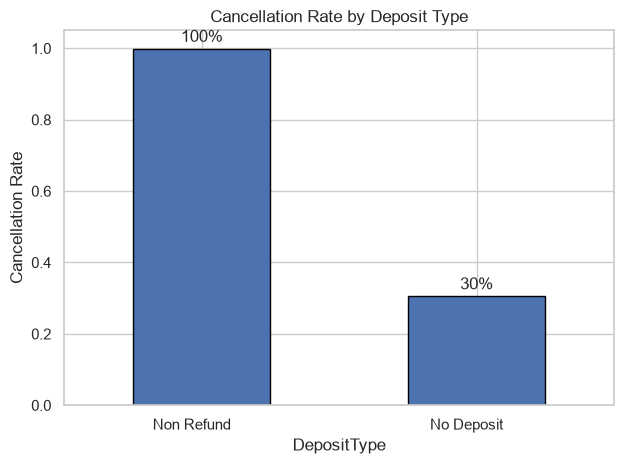

In [310]:
cancel_rate_bar("DepositType", "Cancellation Rate by Deposit Type", min_count=100)

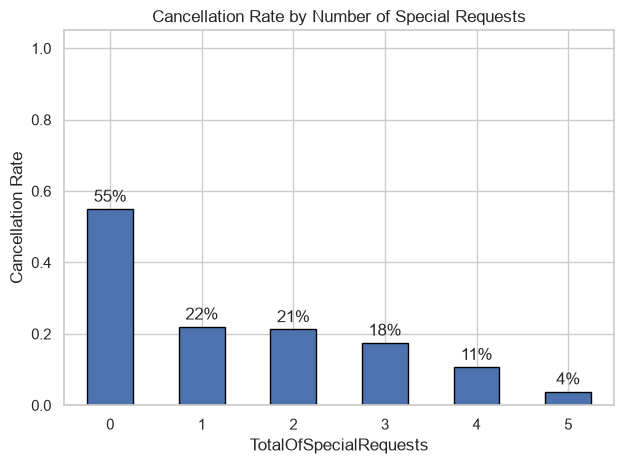

In [311]:
cancel_rate_bar("TotalOfSpecialRequests", "Cancellation Rate by Number of Special Requests")

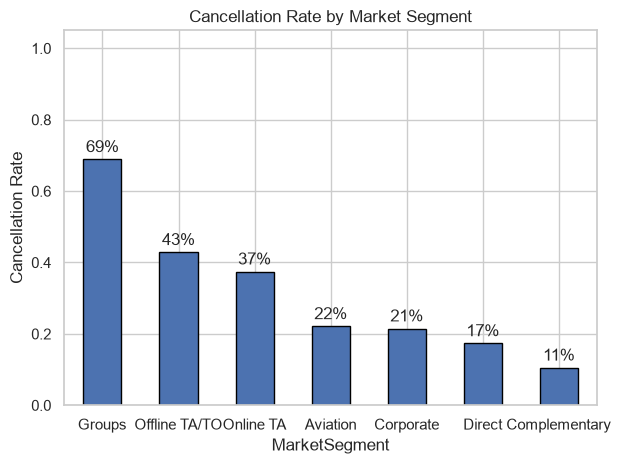

In [312]:
cancel_rate_bar("MarketSegment", "Cancellation Rate by Market Segment", min_count=100)

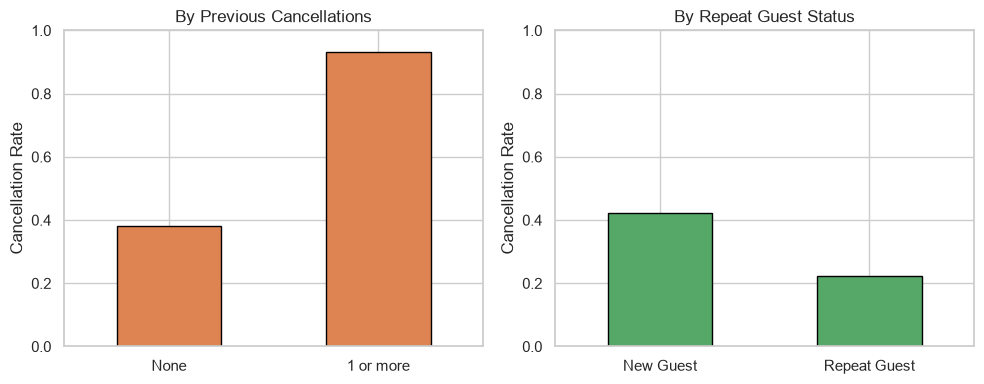

In [313]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

prev = df.groupby(df["PreviousCancellations"] > 0)["IsCanceled"].mean()
prev.index = ["None", "1 or more"]
prev.plot(kind="bar", ax=axes[0], color="#DD8452", edgecolor="black")
axes[0].set_title("By Previous Cancellations")

rep = df.groupby("IsRepeatedGuest")["IsCanceled"].mean()
rep.index = ["New Guest", "Repeat Guest"]
rep.plot(kind="bar", ax=axes[1], color="#55A868", edgecolor="black")
axes[1].set_title("By Repeat Guest Status")

for ax in axes:
    ax.set_ylabel("Cancellation Rate")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

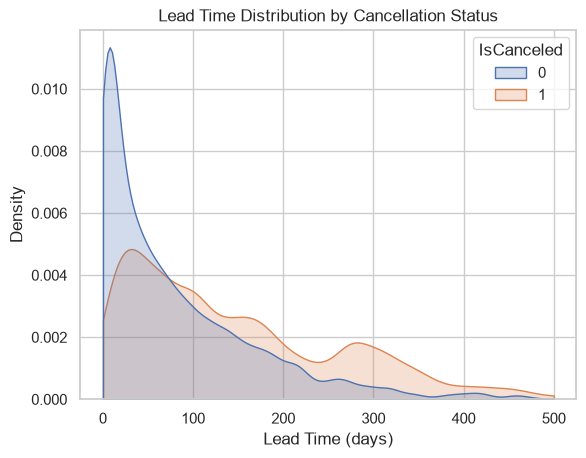

In [314]:
sns.kdeplot(data=df, x="LeadTime", hue="IsCanceled", common_norm=False, fill=True, clip=(0, 500))
plt.title("Lead Time Distribution by Cancellation Status")
plt.xlabel("Lead Time (days)")
plt.show()

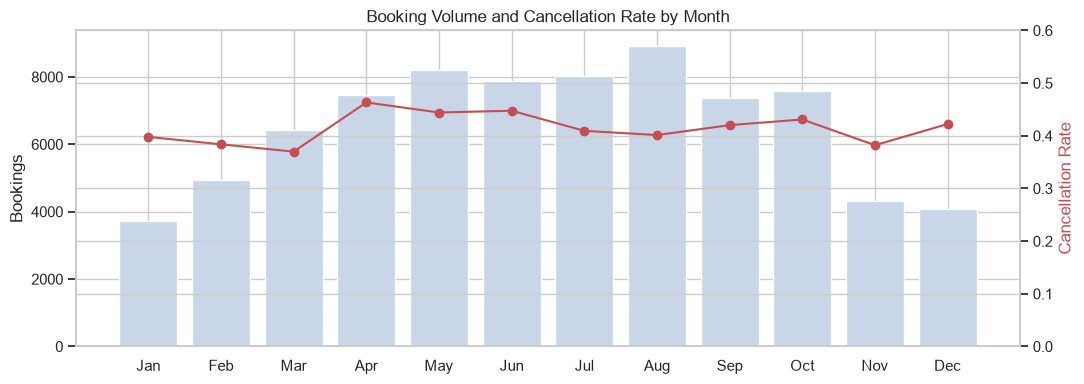

In [315]:
months = ["January","February","March","April","May","June","July",
          "August","September","October","November","December"]
monthly = df.groupby("ArrivalDateMonth").agg(
    bookings=("IsCanceled", "size"), cancel_rate=("IsCanceled", "mean")
).reindex(months)

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(monthly.index.str[:3], monthly["bookings"], color="#C9D6E8")
ax1.set_ylabel("Bookings")
ax2 = ax1.twinx()
ax2.plot(monthly.index.str[:3], monthly["cancel_rate"], color="#C44E52", marker="o")
ax2.set_ylabel("Cancellation Rate", color="#C44E52")
ax2.set_ylim(0, 0.6)
plt.title("Booking Volume and Cancellation Rate by Month")
plt.tight_layout()
plt.show()

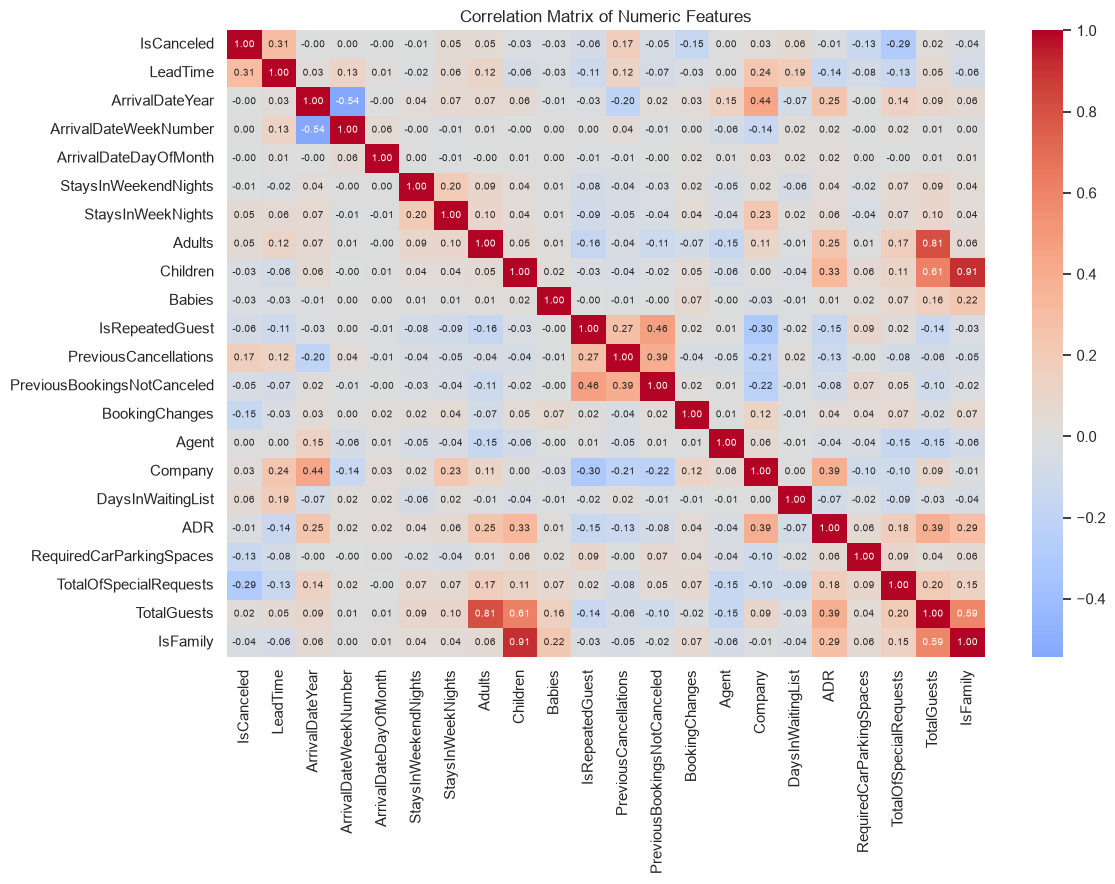

In [316]:
num = df.select_dtypes("number")
plt.figure(figsize=(12, 9))
sns.heatmap(num.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.show()

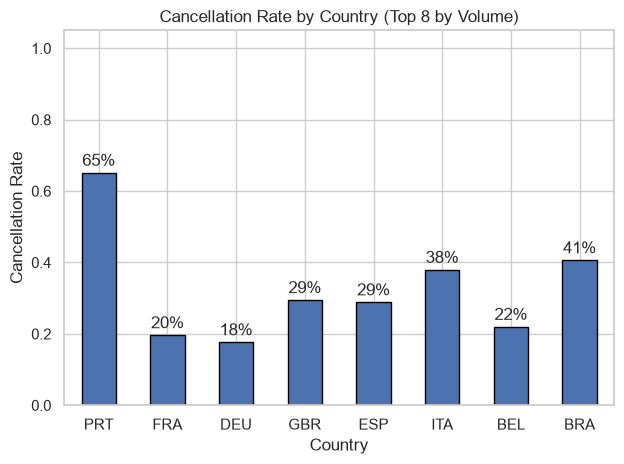

In [317]:
top = df["Country"].value_counts().head(8).index
cancel_rate_bar("Country", "Cancellation Rate by Country (Top 8 by Volume)", order=list(top))

## Logistic Regression Model

In [318]:
df["hasCompany"] = df["Company"].notnull().astype(int)

In [319]:
df["hasAgent"] = df["Agent"].notna().astype(int)

In [320]:
df["TotalNights"] = df["StaysInWeekendNights"] + df["StaysInWeekNights"]

In [321]:
top10 = df['Country'].value_counts().nlargest(10).index
df['Country'] = df['Country'].where(df['Country'].isin(top10), 'Other')

In [322]:
df["Country"].value_counts()

Country
PRT      30814
Other    13267
FRA       8766
DEU       6068
GBR       5292
ESP       4590
ITA       3293
BEL       1878
BRA       1782
USA       1606
NLD       1580
Name: count, dtype: int64

In [323]:
drop_cols = ['ReservationStatus', 'ReservationStatusDate', 'AssignedRoomType',
             'Company', 'Agent', 'ArrivalDateYear',
             'ArrivalDateDayOfMonth', 'ArrivalDateWeekNumber','Children','StaysInWeekendNights','Babies','StaysInWeekNights']

um_cols = ['LeadTime', 'TotalOfSpecialRequests', 'PreviousCancellations',
            'BookingChanges', 'RequiredCarParkingSpaces', 'IsRepeatedGuest',
            'DaysInWaitingList', 'PreviousBookingsNotCanceled',
            'Adults', 'IsFamily', 'ADR']

cat_cols = ['DepositType', 'MarketSegment', 'CustomerType', 'DistributionChannel',
            'Meal', 'ReservedRoomType', 'ArrivalDateMonth', 'Country']

In [324]:
df = df.drop(columns=drop_cols)

In [325]:
df.head()

,IsCanceled,LeadTime,ArrivalDateMonth,Adults,Meal,Country,MarketSegment,DistributionChannel,IsRepeatedGuest,PreviousCancellations,...,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,TotalGuests,IsFamily,hasCompany,hasAgent,TotalNights
0,0,6,July,1,HB,PRT,Offline TA/TO,TA/TO,0,0,...,0,Transient,0.0,0,0,1.0,0,0,1,2
1,1,88,July,2,BB,PRT,Online TA,TA/TO,0,0,...,0,Transient,76.5,0,1,2.0,0,0,1,4
2,1,65,July,1,BB,PRT,Online TA,TA/TO,0,0,...,0,Transient,68.0,0,1,1.0,0,0,1,4
3,1,92,July,2,BB,PRT,Online TA,TA/TO,0,0,...,0,Transient,76.5,0,2,2.0,0,0,1,6
4,1,100,July,2,BB,PRT,Online TA,TA/TO,0,0,...,0,Transient,76.5,0,1,2.0,0,0,1,2


In [326]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

In [327]:
X = df.drop(columns=["IsCanceled"])
y = df["IsCanceled"]

In [328]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [329]:
cat_cols = X.select_dtypes(include=['object','category']).columns
num_cols = X.select_dtypes(include=['number']).columns

C:\Users\ASUS\AppData\Local\Temp\ipykernel_17508\4048927776.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object','category']).columns


In [330]:
processor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

In [331]:
model = Pipeline(steps=[
    ('preprocessor', processor),
    ('classifier', LogisticRegression(max_iter=1000,)),
])

In [332]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['LeadTime','ArrivalDateMonth','Adults',...,'hasCompany','hasAgent', 'TotalNights']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

In [333]:
y_pred = model.predict(X_test)
yprob = model.predict_proba(X_test)[:, 1]

In [334]:
print(classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("ROC AUC Score:", roc_auc_score(y_test, yprob))

              precision    recall  f1-score   support

           0       0.79      0.91      0.85      9189
           1       0.84      0.67      0.74      6599

    accuracy                           0.81     15788
   macro avg       0.82      0.79      0.80     15788
weighted avg       0.81      0.81      0.80     15788

Confusion Matrix:
 [[8343  846]
 [2184 4415]]
ROC AUC Score: 0.8842765001757721
